# 03 · Transformer captioning model: train, evaluate, compare (Phase 7)

The advanced decoder. Instead of one summary vector, it receives the **49 image regions** (the 7 × 7 grid from notebook 01) and, for every word it writes, it decides **which regions to look at**. That mechanism is called **attention**, and we can draw it as a heatmap.

Everything else is kept the same as the LSTM (same features, vocabulary, split, batch size, epoch limit, early stopping and metric code), so the comparison is fair.

**Run it after notebooks 01 and 02.** On Kaggle use a GPU (about 15 to 25 minutes). On a CPU it also works but takes longer (see the timing printed in the training cell).
`LANG = "bn"` trains the Bangla version.

## Setup and settings

In [6]:
import os, json, time, math, random, base64, io
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display, HTML

LANG = "en"            # "en" = English, "bn" = Bangla

CFG = dict(
    d_model=512,       # size of every vector inside the Transformer
    n_heads=8,         # attention heads: 8 different "ways of looking" in parallel
    n_layers=3,        # decoder layers stacked on top of each other
    ff_dim=2048,       # size of the small feed-forward network in each layer
    dropout=0.3,
    batch_size=128,    # same as the LSTM
    lr=3e-4,           # similar to the LSTM (4e-4)
    warmup_steps=200,  # learning rate rises gently at the start, which keeps early training stable
    max_epochs=20,     # same as the LSTM
    patience=3,        # same as the LSTM
    grad_clip=5.0,
    beam_size=3,
)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| language:", LANG)

device: cpu | language: en


## Load the files from notebook 01

In [7]:
ON_KAGGLE = Path("/kaggle/input").exists()
ROOTS = [Path("/kaggle/input")] if ON_KAGGLE else [Path("../data/processed"), Path("../data"), Path("../checkpoints")]
OUT = Path("/kaggle/working") if ON_KAGGLE else Path("../checkpoints")
OUT.mkdir(parents=True, exist_ok=True)

def find(name, want_dir=False):
    for root in ROOTS:
        if root.exists():
            for dirpath, dirnames, filenames in os.walk(root):
                if (want_dir and name in dirnames) or (not want_dir and name in filenames):
                    return Path(dirpath) / name
    return None

PREP = find(f"vocab_{LANG}.json").parent
IMG_DIR = find("Images", want_dir=True)

images = json.load(open(PREP / "images.json", encoding="utf-8"))
pos    = {name: i for i, name in enumerate(images)}
vocab  = json.load(open(PREP / f"vocab_{LANG}.json", encoding="utf-8"))
itos, MAX_WORDS = vocab["itos"], vocab["max_words"]
PAD, START, END, UNK = 0, 1, 2, 3
enc    = np.load(PREP / f"encoded_{LANG}.npz")
ids, img_idx, split = enc["ids"], enc["img_idx"], enc["split"]
caps   = pd.read_csv(PREP / "captions_split.csv", encoding="utf-8")

t0 = time.time()
grid = torch.from_numpy(np.load(PREP / "feats_grid.npy"))          # (8091, 49, 2048) float16, about 1.6 GB of memory
print(f"grid features {tuple(grid.shape)} {grid.dtype} loaded in {time.time() - t0:.0f}s | vocabulary {len(itos)}")

grid features (8091, 49, 2048) torch.float16 loaded in 3s | vocabulary 2533


**Expected:** `grid features (8091, 49, 2048) torch.float16`. This needs about 2 GB of free memory.

In [8]:
class CaptionDataset(torch.utils.data.Dataset):
    def __init__(self, which):
        self.rows = np.where(split == which)[0]
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, k):
        r = self.rows[k]
        return grid[img_idx[r]], torch.from_numpy(ids[r]).long()     # (49, 2048) regions + one caption

train_dl = torch.utils.data.DataLoader(CaptionDataset("train"), batch_size=CFG["batch_size"], shuffle=True)
val_dl   = torch.utils.data.DataLoader(CaptionDataset("val"),   batch_size=CFG["batch_size"])
x, y = next(iter(train_dl))
print("one batch:", tuple(x.shape), tuple(y.shape))

one batch: (128, 49, 2048) (128, 22)


**Expected:** `one batch: (128, 49, 2048) (128, 22)`: for each caption, all 49 regions of its photo instead of one vector.

## The model
Each **decoder layer** has three parts:
1. **Masked self-attention:** every word looks at the words before it. The **causal mask** hides future words, so the model cannot cheat by reading the word it should predict.
2. **Cross-attention:** every word looks at the 49 image regions and takes a weighted mix of them. The weights say *where in the photo* the model is looking for this word.
3. **Feed-forward network:** a small network applied to each word separately.

Because attention has no built-in sense of order, **positional encoding** adds a position pattern (sines and cosines) to each word vector. The image regions get a learned position vector too, so the model knows which region is top-left or bottom-right.

In [9]:
class PositionalEncoding(nn.Module):
    def __init__(self, d, max_len=64):
        super().__init__()
        pos_ = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d, 2) * (-math.log(10000.0) / d))
        pe = torch.zeros(max_len, d)
        pe[:, 0::2], pe[:, 1::2] = torch.sin(pos_ * div), torch.cos(pos_ * div)
        self.register_buffer("pe", pe)
    def forward(self, x):                           # x: (B, T, d)
        return x + self.pe[: x.size(1)]

class DecoderLayer(nn.Module):
    def __init__(self, d, heads, ff, p):
        super().__init__()
        self.self_attn  = nn.MultiheadAttention(d, heads, dropout=p, batch_first=True)
        self.cross_attn = nn.MultiheadAttention(d, heads, dropout=p, batch_first=True)
        self.ff = nn.Sequential(nn.Linear(d, ff), nn.ReLU(), nn.Dropout(p), nn.Linear(ff, d))
        self.n1, self.n2, self.n3 = nn.LayerNorm(d), nn.LayerNorm(d), nn.LayerNorm(d)
        self.drop = nn.Dropout(p)

    def forward(self, x, regions, causal_mask, pad_mask=None, want_attn=False):
        h = self.n1(x)
        x = x + self.drop(self.self_attn(h, h, h, attn_mask=causal_mask, key_padding_mask=pad_mask, need_weights=False)[0])
        h = self.n2(x)
        a, w = self.cross_attn(h, regions, regions, need_weights=want_attn)    # w: (B, T, 49) averaged over heads
        x = x + self.drop(a)
        x = x + self.drop(self.ff(self.n3(x)))
        return x, w

class TransformerCaptioner(nn.Module):
    def __init__(self, vocab_size, feat_dim=2048, d=512, heads=8, layers=3, ff=2048, p=0.3):
        super().__init__()
        self.img_proj = nn.Sequential(nn.Linear(feat_dim, d), nn.ReLU(), nn.Dropout(p))
        self.region_pos = nn.Parameter(torch.zeros(1, 49, d))               # learned position of each region
        self.img_norm = nn.LayerNorm(d)
        self.embed = nn.Embedding(vocab_size, d, padding_idx=PAD)
        self.pos_enc = PositionalEncoding(d)
        self.drop = nn.Dropout(p)
        self.layers = nn.ModuleList([DecoderLayer(d, heads, ff, p) for _ in range(layers)])
        self.norm = nn.LayerNorm(d)
        self.out = nn.Linear(d, vocab_size)
        self.d = d

    def encode_image(self, g):                     # (B, 49, 2048) -> (B, 49, d)
        return self.img_norm(self.img_proj(g.float()) + self.region_pos)

    def decode(self, words, regions, want_attn=False):
        T = words.size(1)
        causal = torch.triu(torch.ones(T, T, dtype=torch.bool, device=words.device), 1)   # True = hidden (future word)
        x = self.drop(self.pos_enc(self.embed(words) * math.sqrt(self.d)))
        pad = words == PAD
        attn = None
        for i, layer in enumerate(self.layers):
            x, w = layer(x, regions, causal, pad, want_attn and i == len(self.layers) - 1)
            if w is not None:
                attn = w
        return self.out(self.norm(x)), attn

    def forward(self, g, words_in):
        return self.decode(words_in, self.encode_image(g))[0]

model = TransformerCaptioner(len(itos), d=CFG["d_model"], heads=CFG["n_heads"], layers=CFG["n_layers"],
                             ff=CFG["ff_dim"], p=CFG["dropout"]).to(DEVICE)
print("trainable parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

trainable parameters: 16,284,645


**Expected:** about 16.3 million trainable parameters, about 2.6 times the LSTM (6.3 million), mostly in the attention and feed-forward layers.

## Training
Same procedure as the LSTM: teacher forcing, cross-entropy that ignores `<pad>`, Adam, gradient clipping, a checkpoint every epoch, early stopping on validation loss. The only addition is a **warm-up**: the learning rate grows from 0 over the first 200 steps, because Transformers can become unstable if they start with full-size updates.

In [10]:
criterion = nn.CrossEntropyLoss(ignore_index=PAD)
optimizer = torch.optim.Adam(model.parameters(), lr=CFG["lr"])
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda step: min(1.0, (step + 1) / CFG["warmup_steps"]))

def run_epoch(dl, train):
    model.train(train)
    total, n = 0.0, 0
    with torch.set_grad_enabled(train):
        for b, (g, y) in enumerate(dl):
            g, y = g.to(DEVICE), y.to(DEVICE)
            logits = model(g, y[:, :-1])
            loss = criterion(logits.reshape(-1, logits.size(-1)), y[:, 1:].reshape(-1))
            if train:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
                optimizer.step(); scheduler.step()
                if epoch == 1 and b == 9:
                    per_batch = (time.time() - t0) / 10
                    print(f"  about {per_batch * len(dl) / 60:.1f} min per epoch on {DEVICE}")
            total += loss.item() * len(y); n += len(y)
    return total / n

best_path, last_path = OUT / f"transformer_{LANG}_best.pt", OUT / f"transformer_{LANG}_last.pt"
def save(path, epoch, val_loss):
    torch.save({"model": model.state_dict(), "cfg": CFG, "itos": itos, "max_words": MAX_WORDS,
                "lang": LANG, "epoch": epoch, "val_loss": val_loss}, path)

history, best, bad_epochs = [], float("inf"), 0
for epoch in range(1, CFG["max_epochs"] + 1):
    t0 = time.time()
    tr = run_epoch(train_dl, True)
    va = run_epoch(val_dl, False)
    history.append({"epoch": epoch, "train_loss": tr, "val_loss": va})
    save(last_path, epoch, va)
    flag = ""
    if va < best:
        best, bad_epochs, flag = va, 0, "  <- best, saved"
        save(best_path, epoch, va)
    else:
        bad_epochs += 1
    print(f"epoch {epoch:2d} | train {tr:.3f} | val {va:.3f} | {time.time() - t0:4.0f}s{flag}")
    if bad_epochs >= CFG["patience"]:
        print(f"early stopping: no improvement for {CFG['patience']} epochs")
        break
pd.DataFrame(history).to_csv(OUT / f"history_transformer_{LANG}.csv", index=False)

  about 4.2 min per epoch on cpu
epoch  1 | train 5.438 | val 4.008 |  247s  <- best, saved
epoch  2 | train 3.778 | val 3.537 |  251s  <- best, saved
epoch  3 | train 3.411 | val 3.289 |  243s  <- best, saved
epoch  4 | train 3.166 | val 3.143 |  240s  <- best, saved
epoch  5 | train 3.000 | val 3.055 |  240s  <- best, saved
epoch  6 | train 2.875 | val 2.984 |  240s  <- best, saved
epoch  7 | train 2.770 | val 2.950 |  240s  <- best, saved
epoch  8 | train 2.681 | val 2.921 |  240s  <- best, saved
epoch  9 | train 2.604 | val 2.902 |  241s  <- best, saved
epoch 10 | train 2.535 | val 2.897 |  240s  <- best, saved
epoch 11 | train 2.473 | val 2.891 |  239s  <- best, saved
epoch 12 | train 2.416 | val 2.887 |  239s  <- best, saved
epoch 13 | train 2.366 | val 2.901 |  239s
epoch 14 | train 2.318 | val 2.898 |  239s
epoch 15 | train 2.272 | val 2.928 |  239s
early stopping: no improvement for 3 epochs


**Expected:** a time estimate after 10 batches, then one line per epoch. The Transformer usually reaches a lower validation loss than the LSTM in fewer epochs, then starts to overfit, so early stopping is more likely to trigger here.

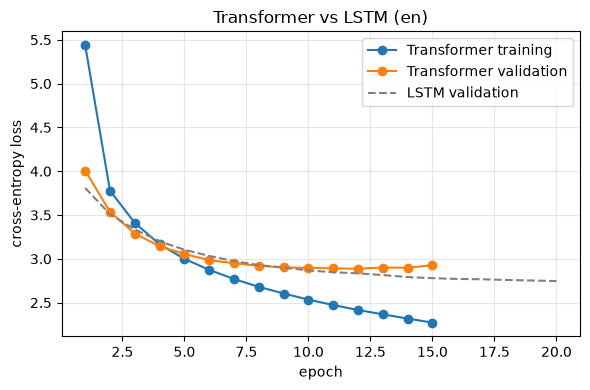

In [11]:
h = pd.DataFrame(history)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(h.epoch, h.train_loss, "o-", label="Transformer training")
ax.plot(h.epoch, h.val_loss, "o-", label="Transformer validation")
lstm_hist = find(f"history_lstm_{LANG}.csv")
if lstm_hist:
    l = pd.read_csv(lstm_hist)
    ax.plot(l.epoch, l.val_loss, "--", color="grey", label="LSTM validation")
ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy loss"); ax.set_title(f"Transformer vs LSTM ({LANG})")
ax.grid(alpha=.3); ax.legend()
fig.tight_layout(); fig.savefig(OUT / f"loss_transformer_{LANG}.png", dpi=200); plt.show()

## Generating captions
Same two strategies as the LSTM. The Transformer re-reads the whole caption so far at every step (instead of carrying a memory), so generating is a little slower.

In [12]:
ckpt = torch.load(best_path, map_location=DEVICE)
model.load_state_dict(ckpt["model"]); model.eval()
print("loaded best model from epoch", ckpt["epoch"])
BLOCKED = [PAD, START, UNK]                       # never write these

def to_words(seq):
    out = []
    for i in seq:
        if i == END: break
        if i not in (PAD, START): out.append(itos[i])
    return out

@torch.no_grad()
def greedy(g_batch, max_len=MAX_WORDS + 1, want_attn=False):
    regions = model.encode_image(g_batch.to(DEVICE))
    words = torch.full((len(g_batch), 1), START, device=DEVICE)
    attn = None
    for _ in range(max_len):
        logits, attn = model.decode(words, regions, want_attn)
        logits = logits[:, -1]
        logits[:, BLOCKED] = -float("inf")
        words = torch.cat([words, logits.argmax(-1, keepdim=True)], 1)
    seqs = [to_words(s) for s in words[:, 1:].tolist()]
    return (seqs, attn) if want_attn else seqs

@torch.no_grad()
def beam_search(g, k=CFG["beam_size"], max_len=MAX_WORDS + 1):
    regions = model.encode_image(g.unsqueeze(0).to(DEVICE))
    beams, done = [([START], 0.0)], []
    for _ in range(max_len):
        words = torch.tensor([b[0] for b in beams], device=DEVICE)
        logits, _ = model.decode(words, regions.expand(len(beams), -1, -1))
        logits = logits[:, -1]
        logits[:, BLOCKED] = -float("inf")
        top_lp, top_w = F.log_softmax(logits, -1).topk(k, -1)
        cand = []
        for bi, (seq, score) in enumerate(beams):
            for j in range(k):
                w, s = top_w[bi, j].item(), score + top_lp[bi, j].item()
                if w == END:
                    done.append((seq, s))                    # finished caption
                else:
                    cand.append((seq + [w], s))              # still growing
        if len(done) >= k or not cand:
            break
        beams = sorted(cand, key=lambda b: b[1], reverse=True)[:k]
    if not done:
        done = beams
    return to_words(max(done, key=lambda d: d[1] / len(d[0]))[0])

test_imgs = sorted(set(caps[caps.split == "test"].image))
G_test = grid[[pos[i] for i in test_imgs]]
for name, g in list(zip(test_imgs, G_test))[:3]:
    print(name)
    print("  greedy:", " ".join(greedy(g.unsqueeze(0))[0]))
    print("  beam  :", " ".join(beam_search(g)))
    print("  human :", caps[caps.image == name][f"{LANG}_tok"].iloc[0])

loaded best model from epoch 12
1056338697_4f7d7ce270.jpg
  greedy: a woman in a blue shirt is riding a bike
  beam  : a woman in a blue shirt is sitting on a bike
  human : a blond woman in a blue shirt appears to wait for a ride
106490881_5a2dd9b7bd.jpg
  greedy: a boy in a blue shirt is standing in the water
  beam  : a boy in a blue shirt is standing in the water
  human : a boy in his blue swim shorts at the beach
1082379191_ec1e53f996.jpg
  greedy: a man in a blue shirt and a blue shirt is sitting on a bench
  beam  : a man in a blue shirt is sitting on a bench
  human : a lady and a man with no shirt sit on a dock


## Scores, and the comparison with the LSTM
Same metric code and the same 1,000 test photos as notebook 02.

In [13]:
from pycocoevalcap.bleu.bleu import Bleu
from pycocoevalcap.rouge.rouge import Rouge
from pycocoevalcap.cider.cider import Cider

refs = {i: caps[caps.image == i][f"{LANG}_tok"].tolist() for i in test_imgs}

class NltkMeteor:
    def __init__(self):
        import nltk
        from nltk.translate.meteor_score import meteor_score
        for pkg in ["wordnet", "omw-1.4"]:
            nltk.download(pkg, quiet=True)
        self.f = meteor_score; self.f([["a", "dog"]], ["a", "dog"])
    def compute_score(self, gts, res):
        s = [self.f([r.split() for r in gts[k]], res[k][0].split()) for k in gts]
        return float(np.mean(s)), s

def meteor_scorer():
    if LANG != "en":
        return None
    try:
        from pycocoevalcap.meteor.meteor import Meteor
        m = Meteor(); m.compute_score({"a": ["a dog"]}, {"a": ["a dog"]}); return m
    except Exception:
        pass
    try:
        return NltkMeteor()
    except Exception:
        return None
METEOR = meteor_scorer()

def score(hyps):
    res = {i: [" ".join(hyps[i]) if hyps[i] else "a"] for i in test_imgs}
    gts = {i: refs[i] for i in test_imgs}
    b, _ = Bleu(4).compute_score(gts, res, verbose=0)
    r, _ = Rouge().compute_score(gts, res)
    c, per_img = Cider().compute_score(gts, res)
    m = METEOR.compute_score(gts, res)[0] if METEOR else float("nan")
    return ({"BLEU-1": b[0], "BLEU-2": b[1], "BLEU-3": b[2], "BLEU-4": b[3], "METEOR": m, "ROUGE-L": r, "CIDEr": c},
            dict(zip(sorted(gts), per_img)))

t0 = time.time()
greedy_hyp = {}
for s in range(0, len(test_imgs), 100):
    for name, words in zip(test_imgs[s:s + 100], greedy(G_test[s:s + 100])):
        greedy_hyp[name] = words
beam_hyp = {}
for n_done, (name, g) in enumerate(zip(test_imgs, G_test), 1):
    beam_hyp[name] = beam_search(g)
    if n_done % 250 == 0:
        print(f"  beam search {n_done}/{len(test_imgs)}  {time.time() - t0:.0f}s")

results, per_image = {}, {}
for name, hyp in [("Transformer greedy", greedy_hyp), (f"Transformer beam {CFG['beam_size']}", beam_hyp)]:
    results[name], per_image[name] = score(hyp)
table = pd.DataFrame(results).T
table.round(3).to_csv(OUT / f"results_transformer_{LANG}.csv")

lstm_res = find(f"results_lstm_{LANG}.csv")
if lstm_res:
    table = pd.concat([pd.read_csv(lstm_res, index_col=0), table])
display(table.round(3))

  beam search 250/1000  33s
  beam search 500/1000  47s
  beam search 750/1000  60s
  beam search 1000/1000  73s


,BLEU-1,BLEU-2,BLEU-3,BLEU-4,METEOR,ROUGE-L,CIDEr
Nearest neighbour,0.437,0.252,0.145,0.084,0.150,0.344,0.246
LSTM greedy,0.569,0.387,0.252,0.163,0.188,0.436,0.411
LSTM beam 3,0.609,0.421,0.286,0.196,0.193,0.449,0.472
Transformer greedy,0.594,0.409,0.271,0.176,0.194,0.450,0.467
Transformer beam 3,0.615,0.428,0.289,0.193,0.196,0.453,0.493


**How to read it:** the rows from `results_lstm_{LANG}.csv` come from notebook 02, the Transformer rows from this run. Both used identical inputs and scoring, so any difference comes from the decoder. On Flickr8k, attention-based models usually gain most on CIDEr and BLEU-4, but with only 6,000 training photos the gap can be small. Either outcome is a valid result for the report.

## Where does the model look? Attention heatmaps
For each generated word we take the cross-attention weights of the last decoder layer (averaged over the 8 heads), reshape them to the 7 × 7 grid, stretch them to the photo's size and draw them on top. Bright areas are the regions the model used for that word.

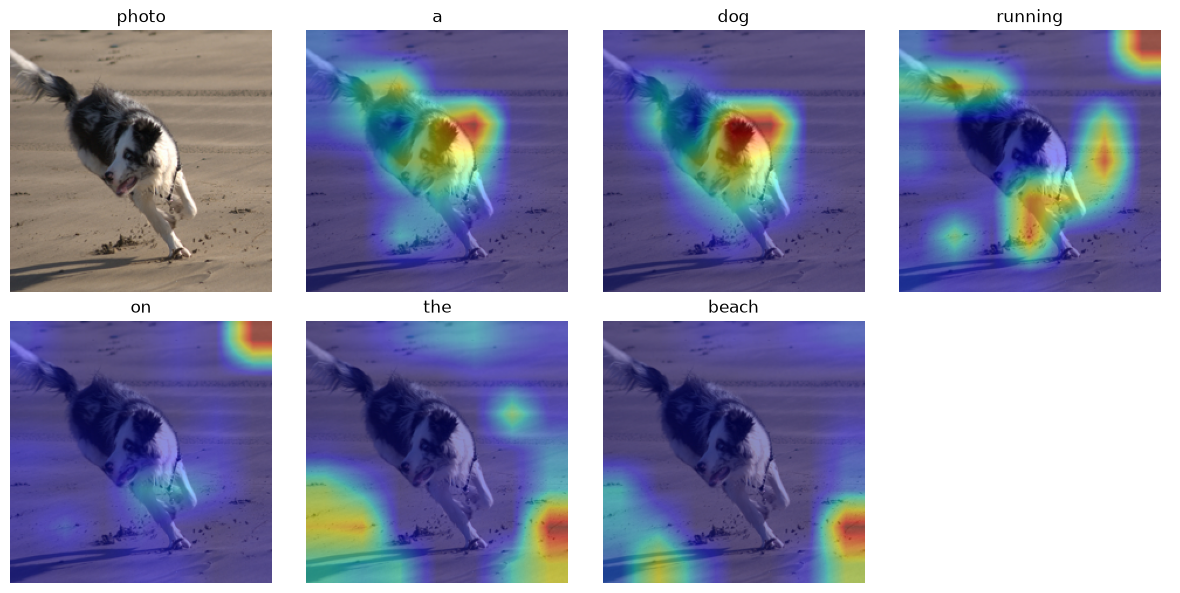

caption: a dog running on the beach


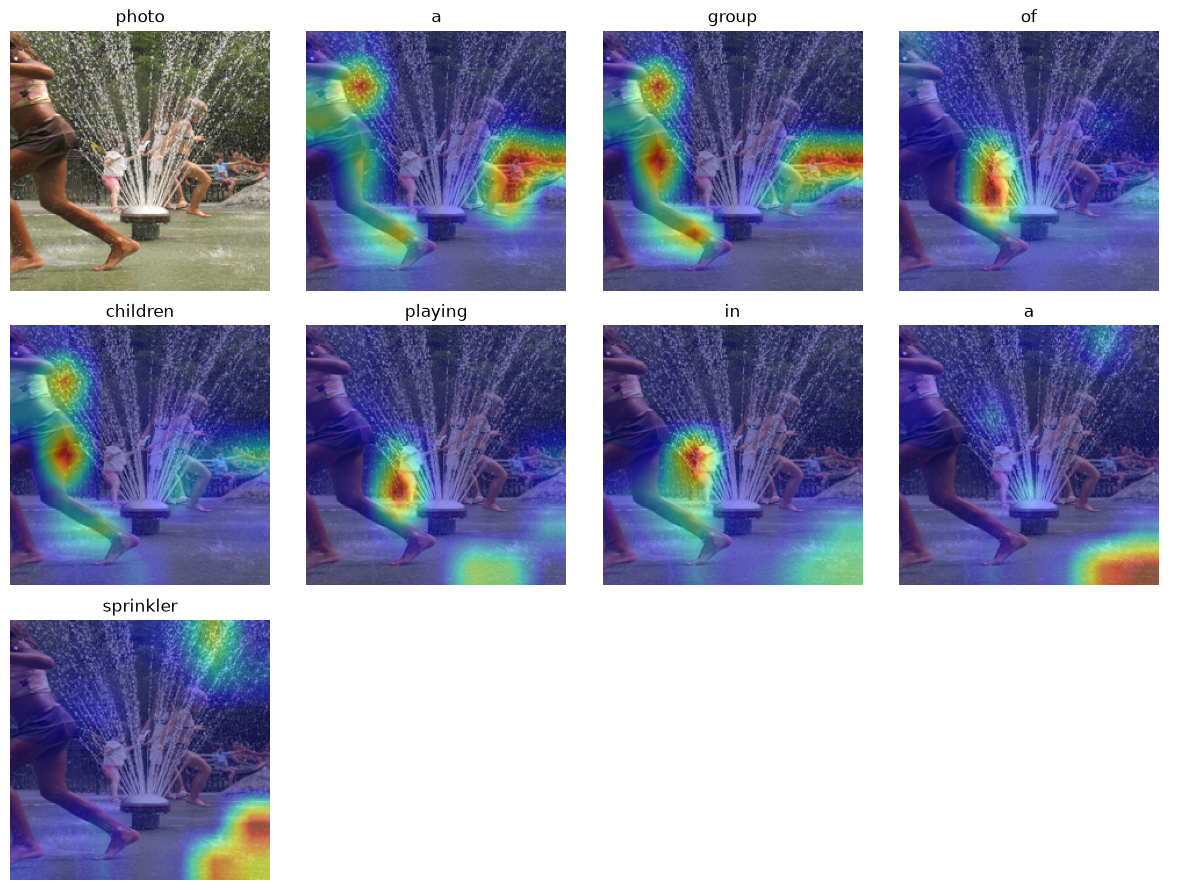

caption: a group of children playing in a sprinkler


In [14]:
from PIL import Image

def show_attention(name, max_words=8):
    if IMG_DIR is None or not (IMG_DIR / name).exists():
        print("photos not available in this environment"); return
    g = grid[pos[name]].unsqueeze(0)
    (words,), attn = greedy(g, want_attn=True)
    words = words[:max_words]
    with Image.open(IMG_DIR / name) as im:
        img = np.asarray(im.convert("RGB").resize((224, 224)))
    cols = min(4, len(words) + 1)
    rows = math.ceil((len(words) + 1) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows))
    axes = np.atleast_1d(axes).ravel()
    axes[0].imshow(img); axes[0].set_title("photo"); axes[0].axis("off")
    for t, w in enumerate(words):
        heat = attn[0, t].reshape(7, 7).float().cpu().numpy()
        heat = np.asarray(Image.fromarray((heat / heat.max() * 255).astype(np.uint8)).resize((224, 224), Image.BILINEAR))
        ax = axes[t + 1]
        ax.imshow(img); ax.imshow(heat, cmap="jet", alpha=0.45); ax.axis("off")
        ax.set_title(w if LANG == "en" else f"word {t + 1}")      # matplotlib cannot draw Bangla letters correctly
    for ax in axes[len(words) + 1:]:
        ax.axis("off")
    fig.tight_layout(); fig.savefig(OUT / f"attention_{LANG}_{name.split('.')[0]}.png", dpi=150); plt.show()
    print("caption:", " ".join(words))

best_names = [n for n, _ in sorted(per_image[f"Transformer beam {CFG['beam_size']}"].items(), key=lambda kv: -kv[1])[:2]]
for n in best_names:
    show_attention(n)

**What to look for:** for object words such as "dog" or "man", the bright area should sit on that object; for words like "a" or "is" the attention is usually spread out, because those words do not depend on the image. This is the kind of evidence the LSTM cannot give.

## Saved files
`transformer_{LANG}_best.pt`, `history_transformer_{LANG}.csv`, `loss_transformer_{LANG}.png`, `results_transformer_{LANG}.csv`, `attention_{LANG}_*.png`.

### Questions for the team
1. What is the difference between self-attention and cross-attention in this model?
2. Why is the causal mask needed during training?
3. Why does the Transformer need positional encoding, but the LSTM does not?
4. What does the attention heatmap show, and why is it useful in the report?
5. Which decoder scored better, and did it win on every metric?